In [ ]:

#======================================================
#Импорт библиотек
#======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
#======================================================
#Загрузка данных
#======================================================


df = pd.read_csv('heart.csv')
print(df.head())

print("Размерность БД:", df.shape)

print("Информация БД:")
print(df.info())

print("Пропущенные значения:")
print(df.isnull().sum())

print("Статистика БД:")
print(df.describe())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
Размерность БД: (1025, 14)
Информация БД:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64 

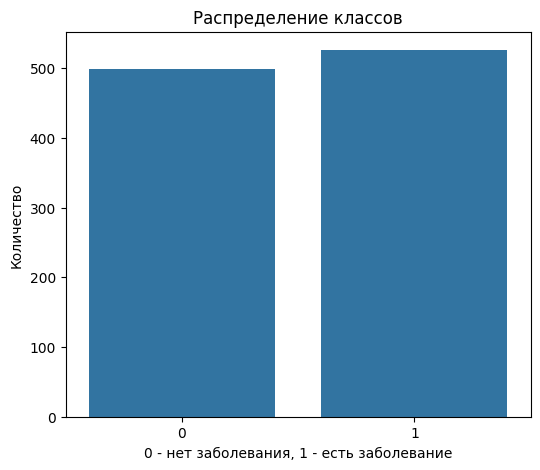

In [ ]:
#======================================================
#Анализ данных
#======================================================

plt.figure(figsize=(6,5))
sns.countplot(x='target', data=df)

plt.title("Распределение классов")
plt.xlabel("0 - нет заболевания, 1 - есть заболевание")
plt.ylabel("Количество")

plt.show()

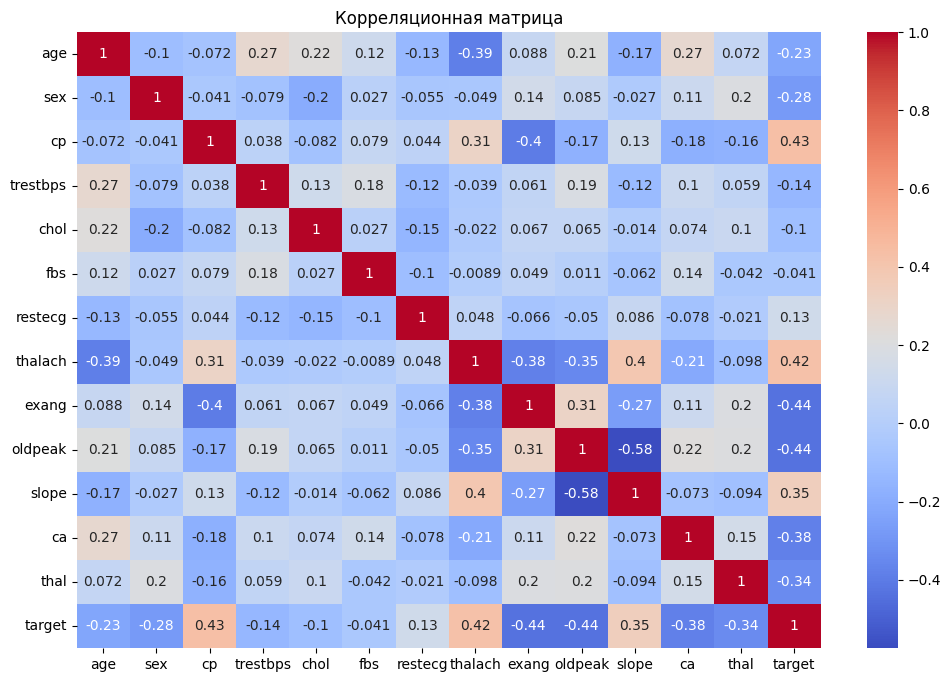

In [ ]:
#======================================================
#Корреляционная матрица
#======================================================
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Корреляционная матрица")

plt.show()

In [ ]:
#======================================================
#Подготовка данных
#======================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
!pip install xgboost

In [ ]:
#======================================================
#Модели
#======================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)


models = {
    "Logistic Regression":
    LogisticRegression(),

    "Random Forest":
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM":
    SVC(
        probability=True
    ),

    "XGBoost":
    XGBClassifier(
        random_state=42
    )
}

results=[]

for name, model in models.items():

    print("="*50)
    print(name)

    if name in [
        "Logistic Regression",
        "SVM"
    ]:

        model.fit(
            X_train_scaled,
            y_train
        )

        predictions=model.predict(
            X_test_scaled
        )

        probabilities=model.predict_proba(
            X_test_scaled
        )[:,1]

    else:

        model.fit(
            X_train,
            y_train
        )

        predictions=model.predict(
            X_test
        )

        probabilities=model.predict_proba(
            X_test
        )[:,1]



    accuracy=accuracy_score(
        y_test,
        predictions
    )

    auc=roc_auc_score(
        y_test,
        probabilities
    )


    results.append([
        name,
        accuracy,
        auc
    ])


    print(
        classification_report(
            y_test,
            predictions
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.72      0.78       102
           1       0.76      0.87      0.81       103

    accuracy                           0.80       205
   macro avg       0.80      0.79      0.79       205
weighted avg       0.80      0.80      0.79       205

Random Forest
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

SVM
              precision    recall  f1-score   support

           0       0.93      0.83      0.88       102
           1       0.85      0.94      0.89       103

    accuracy                           0.89       205
   macro avg       0.89      0.89      0.89       205
weighted avg       0.89      0.89   

                 Model  Accuracy   ROC_AUC
0  Logistic Regression  0.795122  0.878736
1        Random Forest  0.985366  1.000000
2                  SVM  0.887805  0.963164
3              XGBoost  0.985366  0.989435


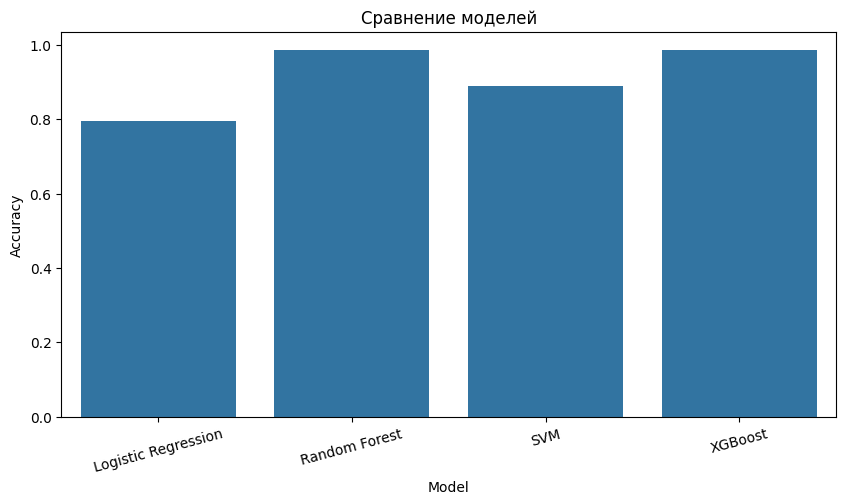

In [ ]:
#======================================================
#Сравнение этих моделей
#======================================================

results_df=pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "ROC_AUC"
    ]
)

print(results_df)

plt.figure(figsize=(10,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results_df
)

plt.title(
    "Сравнение моделей"
)

plt.xticks(rotation=15)

plt.show()

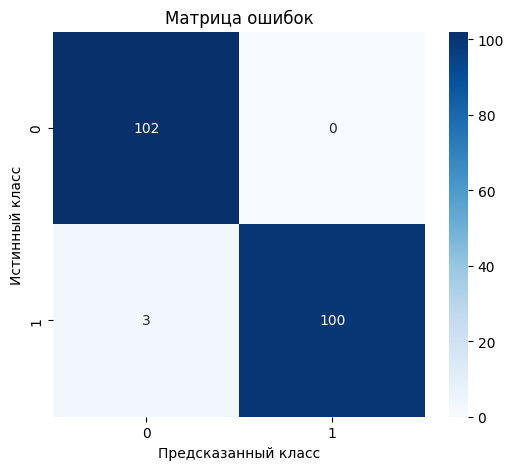

In [ ]:
#======================================================
#Матрица ошибок
#======================================================
best_model=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

best_model.fit(
    X_train,
    y_train
)

pred=best_model.predict(
    X_test
)

cm=confusion_matrix(
    y_test,
    pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(
    "Матрица ошибок"
)

plt.xlabel(
    "Предсказанный класс"
)

plt.ylabel(
    "Истинный класс"
)

plt.show()

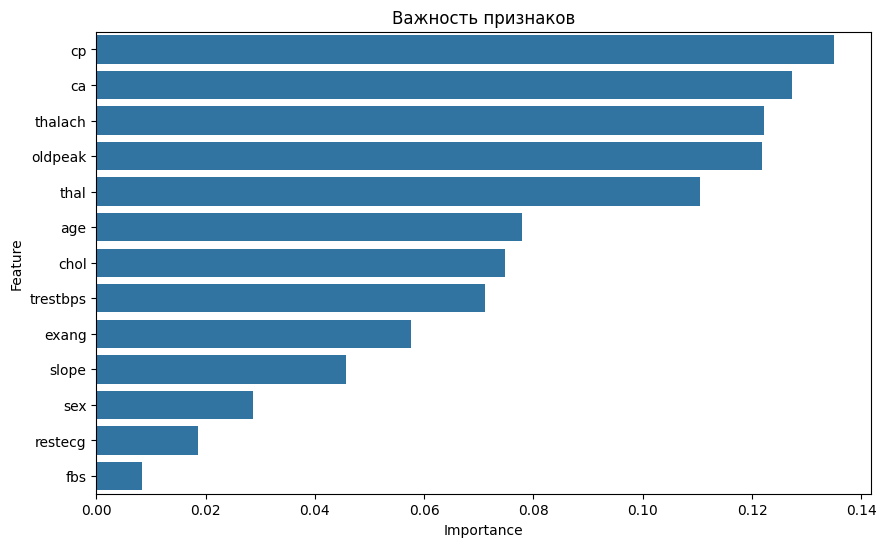

In [ ]:
#======================================================
#Важность признаков
#======================================================

importance=best_model.feature_importances_

feature_importance=pd.DataFrame({

    'Feature':X.columns,
    'Importance':importance

})

feature_importance=feature_importance.sort_values(
    by='Importance',
    ascending=False
)


plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title(
    "Важность признаков"
)

plt.show()

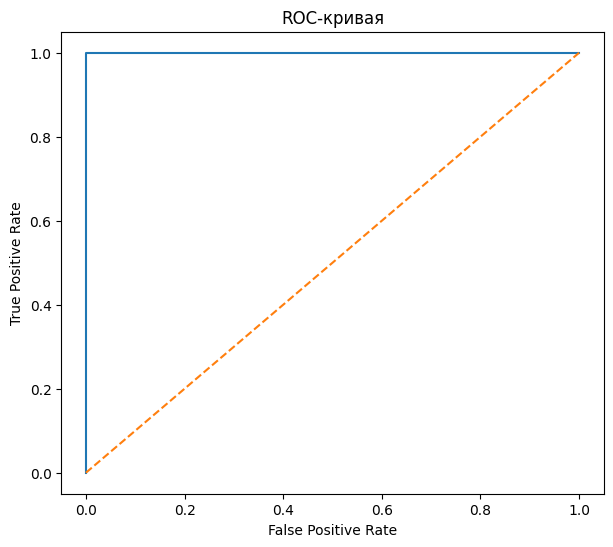

In [ ]:
#======================================================
#ROC-кривая
#======================================================

probs=best_model.predict_proba(
    X_test
)[:,1]

fpr,tpr,_=roc_curve(
    y_test,
    probs
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.title(
    'ROC-кривая'
)

plt.xlabel(
    'False Positive Rate'
)

plt.ylabel(
    'True Positive Rate'
)

plt.show()